In [1]:
!git clone https://github.com/pellungrobe/XAI_course_2024
!pip install shap lime deap interpret aix360 bitarray catboost

Cloning into 'XAI_course_2024'...
remote: Enumerating objects: 4098, done.
remote: Counting objects: 100% (48/48), done.
remote: Compressing objects: 100% (22/22), done.
remote: Total 4098 (delta 30), reused 36 (delta 26), pack-reused 4050
Receiving objects: 100% (4098/4098), 1006.87 MiB | 21.28 MiB/s, done.
Resolving deltas: 100% (450/450), done.
Updating files: 100% (3055/3055), done.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 535.7/535.7 kB 6.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 10.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.4/135.4 kB 11.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 MB 8.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 288.3/288.3 kB 31.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.5/98.5 MB 9.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 60.2 MB/s eta 0:00:

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
ls

drive/  sample_data/  XAI_course_2024/


In [5]:
PATH_TO_INPUT = '/content/drive/MyDrive/Colab Notebooks/phd_data/'

In [6]:
cd XAI_course_2024

/content/XAI_course_2024


In [7]:
import pickle
import numpy as np
import pandas as pd

from sklearn import preprocessing
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

import lime
import shap
import os
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import catboost as cb

from xailib.data_loaders.dataframe_loader import prepare_dataframe

from xailib.explainers.lime_explainer import LimeXAITabularExplainer
from xailib.explainers.lore_explainer import LoreTabularExplainer
from xailib.explainers.shap_explainer_tab import ShapXAITabularExplainer

from xailib.models.sklearn_classifier_wrapper import sklearn_classifier_wrapper

In [8]:
import torch
from torch.autograd import Variable
import torch.nn.functional as F
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report

# Breat Cancer Model

In [9]:
data = pd.read_csv(PATH_TO_INPUT+'breast_cancer.csv')

In [10]:
data

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [12]:
data.drop(columns=['Unnamed: 32', 'id'], inplace=True)

In [13]:
data

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [14]:
label_encoder = LabelEncoder()
data['diagnosis'] = label_encoder.fit_transform(data['diagnosis'])

In [15]:
data

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,1,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,1,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,1,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,1,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [28]:
features_columns = data.drop(columns=['diagnosis']).columns
print(len(features_columns))
features_columns

30


Index(['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
       'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')

In [29]:
features = data.drop(columns=['diagnosis']).values
labels = data['diagnosis'].values

X_train_, X_test_, y_train_, y_test_ = train_test_split(features, labels, test_size=0.2, random_state=42)

In [35]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import torch
import numpy as np
import random
import os

#To Stabilize results in PyTorch and ensuring reproducibility
def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed(52)

In [36]:
# Convert the data to PyTorch tensors
X_train = torch.tensor(X_train_, dtype=torch.float32)
X_test = torch.tensor(X_test_, dtype=torch.float32)
y_train = torch.tensor(y_train_, dtype=torch.long)
y_test = torch.tensor(y_test_, dtype=torch.long)

In [37]:
# Define the model architecture in PyTorch
class DiseaseClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(DiseaseClassifier, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

    def predict_proba(self, x):
      with torch.no_grad():
        x = torch.tensor(x, dtype=torch.float32)
        pred = torch.nn.functional.softmax(self.forward(x))
        return np.array(pred)

    def predict(self, x):
      with torch.no_grad():
        x = torch.tensor(x, dtype=torch.float32)
        pred = torch.nn.functional.softmax(self.forward(x))
        max_vals, predictions = torch.max(pred, dim=1)
        return np.array(predictions)

# Define the hyperparameters
input_dim = X_train.shape[1]
hidden_dim = 64
output_dim = 2
learning_rate = 0.001
num_epochs = 10
batch_size = 16

# Create an instance of the model
model = DiseaseClassifier(input_dim, hidden_dim, output_dim)

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
# criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Create data loaders for batching
train_dataset = torch.utils.data.TensorDataset(X_train, y_train)
test_dataset = torch.utils.data.TensorDataset(X_test, y_test)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Training loop
for epoch in range(num_epochs):
    running_loss = 0.0
    for inputs, labels in train_loader:
        # Zero the gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)

        # Compute the loss
        loss = criterion(outputs, labels)

        # Backward pass and optimization
        loss.backward()
        optimizer.step()

        # Track the loss
        running_loss += loss.item()

    # Print the average loss for the epoch
    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {running_loss / len(train_loader)}")

Epoch 1/10, Loss: 3.2368830396183608
Epoch 2/10, Loss: 0.40945298198995916
Epoch 3/10, Loss: 0.297892060773126
Epoch 4/10, Loss: 0.2950278181454231
Epoch 5/10, Loss: 0.2794902268154868
Epoch 6/10, Loss: 0.2533795160466227
Epoch 7/10, Loss: 0.2813277505338192
Epoch 8/10, Loss: 0.3465740650506883
Epoch 9/10, Loss: 0.2835655003657629
Epoch 10/10, Loss: 0.3739306811757129


# Data Instances

## Detecting Misclassified, Low Confidence and High Confidence Instances

In [38]:
model.eval()
misclassified_data = []
low_confidence_data = []
high_confidence_data = []

true_labels = []
predicted_labels = []
with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model(inputs)
        probabilities = torch.softmax(outputs, dim=1)
        max_vals, predictions = torch.max(probabilities, dim=1)

        true_labels.extend(labels.numpy())
        predicted_labels.extend(predictions.numpy())
        # print(max_vals)

        # Analyze predictions
        for i, (prob, pred, label) in enumerate(zip(max_vals, predictions, labels)):
            instance_data = {'Input': inputs[i].numpy(), 'True Label': label.item(), 'Predicted Label': pred.item(), 'Confidence': prob.item()}
            if pred != label:
                misclassified_data.append(instance_data)
            if prob.item() < 0.6:  # Threshold for low confidence
                low_confidence_data.append(instance_data)
            elif prob.item() > 0.9:  # Threshold for high confidence
                high_confidence_data.append(instance_data)

# Convert lists to DataFrames
df_misclassified = pd.DataFrame(misclassified_data)
df_low_confidence = pd.DataFrame(low_confidence_data)
df_high_confidence = pd.DataFrame(high_confidence_data)

# Display or save the DataFrames as needed
print("Misclassified Instances:")
print(len(df_misclassified),len(df_low_confidence),len(df_high_confidence))

Misclassified Instances:
8 6 75


In [39]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

accuracy = accuracy_score(true_labels, predicted_labels)
precision, recall, f1, _ = precision_recall_fscore_support(true_labels, predicted_labels, average='binary')

print(f'Accuracy: {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'F1 Score: {f1:.4f}')

Accuracy: 0.9298
Precision: 0.8431
Recall: 1.0000
F1 Score: 0.9149


In [40]:
df_misclassified

,Input,True Label,Predicted Label,Confidence
0,"[12.47, 18.6, 81.09, 481.9, 0.09965, 0.1058, 0...",0,1,0.888754
1,"[13.68, 16.33, 87.76, 575.5, 0.09277, 0.07255,...",0,1,0.848780
2,"[14.62, 24.02, 94.57, 662.7, 0.08974, 0.08606,...",0,1,0.580094
3,"[13.94, 13.17, 90.31, 594.2, 0.1248, 0.09755, ...",0,1,0.542406
4,"[13.46, 18.75, 87.44, 551.1, 0.1075, 0.1138, 0...",0,1,0.530924
5,"[15.04, 16.74, 98.73, 689.4, 0.09883, 0.1364, ...",0,1,0.800873
6,"[10.82, 24.21, 68.89, 361.6, 0.08192, 0.06602,...",0,1,0.568563
7,"[14.64, 16.85, 94.21, 666.0, 0.08641, 0.06698,...",0,1,0.640726


In [41]:
df_low_confidence

,Input,True Label,Predicted Label,Confidence
0,"[14.81, 14.7, 94.66, 680.7, 0.08472, 0.05016, ...",0,0,0.528649
1,"[14.62, 24.02, 94.57, 662.7, 0.08974, 0.08606,...",0,1,0.580094
2,"[13.94, 13.17, 90.31, 594.2, 0.1248, 0.09755, ...",0,1,0.542406
3,"[13.17, 18.22, 84.28, 537.3, 0.07466, 0.05994,...",0,0,0.528571
4,"[13.46, 18.75, 87.44, 551.1, 0.1075, 0.1138, 0...",0,1,0.530924
5,"[10.82, 24.21, 68.89, 361.6, 0.08192, 0.06602,...",0,1,0.568563


In [42]:
df_high_confidence

,Input,True Label,Predicted Label,Confidence
0,"[18.94, 21.31, 123.6, 1130.0, 0.09009, 0.1029,...",1,1,1.000000
1,"[15.46, 19.48, 101.7, 748.9, 0.1092, 0.1223, 0...",1,1,0.999976
2,"[12.4, 17.68, 81.47, 467.8, 0.1054, 0.1316, 0....",0,0,0.966502
3,"[11.54, 14.44, 74.65, 402.9, 0.09984, 0.112, 0...",0,0,0.948994
4,"[20.6, 29.33, 140.1, 1265.0, 0.1178, 0.277, 0....",1,1,1.000000
...,...,...,...,...
70,"[12.34, 22.22, 79.85, 464.5, 0.1012, 0.1015, 0...",0,0,0.932057
71,"[23.09, 19.83, 152.1, 1682.0, 0.09342, 0.1275,...",1,1,1.000000
72,"[16.07, 19.65, 104.1, 817.7, 0.09168, 0.08424,...",1,1,0.999994
73,"[11.52, 14.93, 73.87, 406.3, 0.1013, 0.07808, ...",0,0,0.927175


In [43]:
misclassified_inputs = [data['Input'] for data in misclassified_data]  # Extracting inputs
low_confidence_inputs = [data['Input'] for data in low_confidence_data]
high_confidence_inputs = [data['Input'] for data in high_confidence_data]
# Convert the list of numpy arrays into a single numpy array for easier handling
misclassified_inputs_array = np.array(misclassified_inputs)
low_confidence_inputs_array = np.array(low_confidence_inputs)
high_confidence_inputs_array = np.array(high_confidence_inputs)

# Convert this numpy array into a DataFrame
df_misclassified_inputs = pd.DataFrame(misclassified_inputs_array, columns=features_columns)
df_low_confidence_inputs = pd.DataFrame(low_confidence_inputs_array, columns=features_columns)
df_high_confidence_inputs = pd.DataFrame(high_confidence_inputs_array, columns=features_columns)


In [44]:
# Displaying the first few rows of the DataFrame

df_misclassified_inputs

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,12.47,18.600000,81.089996,481.899994,0.09965,0.10580,0.08005,0.03821,0.1925,0.06373,...,14.970000,24.639999,96.050003,677.900024,0.1426,0.2378,0.26710,0.10150,0.3014,0.08750
1,13.68,16.330000,87.760002,575.500000,0.09277,0.07255,0.01752,0.01880,0.1631,0.06155,...,15.850000,20.200001,101.599998,773.400024,0.1264,0.1564,0.12060,0.08704,0.2806,0.07782
2,14.62,24.020000,94.570000,662.700012,0.08974,0.08606,0.03102,0.02957,0.1685,0.05866,...,16.110001,29.110001,102.900002,803.700012,0.1115,0.1766,0.09189,0.06946,0.2522,0.07246
3,13.94,13.170000,90.309998,594.200012,0.12480,0.09755,0.10100,0.06615,0.1976,0.06457,...,14.620000,15.380000,94.519997,653.299988,0.1394,0.1364,0.15590,0.10150,0.2160,0.07253
4,13.46,18.750000,87.440002,551.099976,0.10750,0.11380,0.04201,0.03152,0.1723,0.06317,...,15.350000,25.160000,101.900002,719.799988,0.1624,0.3124,0.26540,0.14270,0.3518,0.08665
5,15.04,16.740000,98.730003,689.400024,0.09883,0.13640,0.07721,0.06142,0.1668,0.06869,...,16.760000,20.430000,109.699997,856.900024,0.1135,0.2176,0.18560,0.10180,0.2177,0.08549
6,10.82,24.209999,68.889999,361.600006,0.08192,0.06602,0.01548,0.00816,0.1976,0.06328,...,13.030000,31.450001,83.900002,505.600006,0.1204,0.1633,0.06194,0.03264,0.3059,0.07626
7,14.64,16.850000,94.209999,666.000000,0.08641,0.06698,0.05192,0.02791,0.1409,0.05355,...,16.459999,25.440001,106.000000,831.000000,0.1142,0.2070,0.24370,0.07828,0.2455,0.06596


In [45]:
# Displaying the first few rows of the DataFrame

df_low_confidence_inputs

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,14.81,14.700000,94.660004,680.700012,0.08472,0.05016,0.03416,0.02541,0.1659,0.05348,...,15.610000,17.580000,101.699997,760.200012,0.1139,0.1011,0.11010,0.07955,0.2334,0.06142
1,14.62,24.020000,94.570000,662.700012,0.08974,0.08606,0.03102,0.02957,0.1685,0.05866,...,16.110001,29.110001,102.900002,803.700012,0.1115,0.1766,0.09189,0.06946,0.2522,0.07246
2,13.94,13.170000,90.309998,594.200012,0.12480,0.09755,0.10100,0.06615,0.1976,0.06457,...,14.620000,15.380000,94.519997,653.299988,0.1394,0.1364,0.15590,0.10150,0.2160,0.07253
3,13.17,18.219999,84.279999,537.299988,0.07466,0.05994,0.04859,0.02870,0.1454,0.05549,...,14.900000,23.889999,95.099998,687.599976,0.1282,0.1965,0.18760,0.10450,0.2235,0.06925
4,13.46,18.750000,87.440002,551.099976,0.10750,0.11380,0.04201,0.03152,0.1723,0.06317,...,15.350000,25.160000,101.900002,719.799988,0.1624,0.3124,0.26540,0.14270,0.3518,0.08665
5,10.82,24.209999,68.889999,361.600006,0.08192,0.06602,0.01548,0.00816,0.1976,0.06328,...,13.030000,31.450001,83.900002,505.600006,0.1204,0.1633,0.06194,0.03264,0.3059,0.07626


In [46]:
df_high_confidence_inputs

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,18.940001,21.309999,123.599998,1130.000000,0.09009,0.10290,0.10800,0.07951,0.1582,0.05461,...,24.860001,26.580000,165.899994,1866.000000,0.1193,0.2336,0.2687,0.17890,0.2551,0.06589
1,15.460000,19.480000,101.699997,748.900024,0.10920,0.12230,0.14660,0.08087,0.1931,0.05796,...,19.260000,26.000000,124.900002,1156.000000,0.1546,0.2394,0.3791,0.15140,0.2837,0.08019
2,12.400000,17.680000,81.470001,467.799988,0.10540,0.13160,0.07741,0.02799,0.1811,0.07102,...,12.880000,22.910000,89.610001,515.799988,0.1450,0.2629,0.2403,0.07370,0.2556,0.09359
3,11.540000,14.440000,74.650002,402.899994,0.09984,0.11200,0.06737,0.02594,0.1818,0.06782,...,12.260000,19.680000,78.779999,457.799988,0.1345,0.2118,0.1797,0.06918,0.2329,0.08134
4,20.600000,29.330000,140.100006,1265.000000,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740000,39.419998,184.600006,1821.000000,0.1650,0.8681,0.9387,0.26500,0.4087,0.12400
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,12.340000,22.219999,79.849998,464.500000,0.10120,0.10150,0.05370,0.02822,0.1551,0.06761,...,13.580000,28.680000,87.360001,553.000000,0.1452,0.2338,0.1688,0.08194,0.2268,0.09082
71,23.090000,19.830000,152.100006,1682.000000,0.09342,0.12750,0.16760,0.10030,0.1505,0.05484,...,30.790001,23.870001,211.500000,2782.000000,0.1199,0.3625,0.3794,0.22640,0.2908,0.07277
72,16.070000,19.650000,104.099998,817.700012,0.09168,0.08424,0.09769,0.06638,0.1798,0.05391,...,19.770000,24.559999,128.800003,1223.000000,0.1500,0.2045,0.2829,0.15200,0.2650,0.06387
73,11.520000,14.930000,73.870003,406.299988,0.10130,0.07808,0.04328,0.02929,0.1883,0.06168,...,12.650000,21.190001,80.879997,491.799988,0.1389,0.1582,0.1804,0.09608,0.2664,0.07809


## Selection of 10 Instances

**We selected 03 instances with misclassified output, 03 with low confidence and 4 with high confidence.**

In [47]:
mis = df_misclassified_inputs[:3]
low = df_low_confidence_inputs[:3]
high = df_high_confidence_inputs[:4]


In [48]:
result = pd.concat([mis, low, high], ignore_index=True)  # Concatenate and reset index
result = result.reindex(range(10))

result

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,12.470000,18.600000,81.089996,481.899994,0.09965,0.10580,0.08005,0.03821,0.1925,0.06373,...,14.970000,24.639999,96.050003,677.900024,0.1426,0.2378,0.26710,0.10150,0.3014,0.08750
1,13.680000,16.330000,87.760002,575.500000,0.09277,0.07255,0.01752,0.01880,0.1631,0.06155,...,15.850000,20.200001,101.599998,773.400024,0.1264,0.1564,0.12060,0.08704,0.2806,0.07782
2,14.620000,24.020000,94.570000,662.700012,0.08974,0.08606,0.03102,0.02957,0.1685,0.05866,...,16.110001,29.110001,102.900002,803.700012,0.1115,0.1766,0.09189,0.06946,0.2522,0.07246
3,14.810000,14.700000,94.660004,680.700012,0.08472,0.05016,0.03416,0.02541,0.1659,0.05348,...,15.610000,17.580000,101.699997,760.200012,0.1139,0.1011,0.11010,0.07955,0.2334,0.06142
4,14.620000,24.020000,94.570000,662.700012,0.08974,0.08606,0.03102,0.02957,0.1685,0.05866,...,16.110001,29.110001,102.900002,803.700012,0.1115,0.1766,0.09189,0.06946,0.2522,0.07246
5,13.940000,13.170000,90.309998,594.200012,0.12480,0.09755,0.10100,0.06615,0.1976,0.06457,...,14.620000,15.380000,94.519997,653.299988,0.1394,0.1364,0.15590,0.10150,0.2160,0.07253
6,18.940001,21.309999,123.599998,1130.000000,0.09009,0.10290,0.10800,0.07951,0.1582,0.05461,...,24.860001,26.580000,165.899994,1866.000000,0.1193,0.2336,0.26870,0.17890,0.2551,0.06589
7,15.460000,19.480000,101.699997,748.900024,0.10920,0.12230,0.14660,0.08087,0.1931,0.05796,...,19.260000,26.000000,124.900002,1156.000000,0.1546,0.2394,0.37910,0.15140,0.2837,0.08019
8,12.400000,17.680000,81.470001,467.799988,0.10540,0.13160,0.07741,0.02799,0.1811,0.07102,...,12.880000,22.910000,89.610001,515.799988,0.1450,0.2629,0.24030,0.07370,0.2556,0.09359
9,11.540000,14.440000,74.650002,402.899994,0.09984,0.11200,0.06737,0.02594,0.1818,0.06782,...,12.260000,19.680000,78.779999,457.799988,0.1345,0.2118,0.17970,0.06918,0.2329,0.08134


In [ ]:
data_tensor = torch.tensor(result.values, dtype=torch.float)

In [ ]:
with torch.no_grad():
    model.eval()
    out = model(data_tensor)
    # print(outputs.data)
    # probabilities = nn.functional.softmax(outputs, dim=1)
    _, predic = torch.max(out.data, 1)
    # # print(torch.max(outputs.data, 1))
    # accur = (predic == y_test).sum().item() / y_test.size(0)
    # print(f"Test Accuracy: {accur}")

In [ ]:
predic = predic.numpy()
predic

array([1, 1, 1, 0, 1, 1, 1, 1, 0, 0])

# LIME

In [ ]:
# explainer = LimeTabularExplainer(X_train, feature_names=iris.feature_names, class_names=iris.target_names, discretize_continuous=True)


In [ ]:
explainer = lime.lime_tabular.LimeTabularExplainer(X_train_, feature_names = features_columns,class_names=['0', '1'], mode='classification')

In [ ]:
# def predict_fn(data):
#     model.eval()
#     with torch.no_grad():
#         data_tensor = torch.tensor(data, dtype=torch.float32)
#         predictions = model(data_tensor).numpy()
#         probabilities = torch.softmax(outputs, dim=1)
#     return probabilities

In [ ]:
def predict_fn(data):
    model.eval()
    with torch.no_grad():
        # Assume data is numpy array; convert it to PyTorch tensor
        data_tensor = torch.tensor(data, dtype=torch.float)
        outputs = model(data_tensor)
        probabilities = torch.softmax(outputs, dim=1).numpy()
    return probabilities

## Misclassified Instances

In [ ]:
exp = explainer.explain_instance(mis.iloc[0].values, predict_fn, num_features=30)
exp.show_in_notebook(show_table=True, show_all=False)

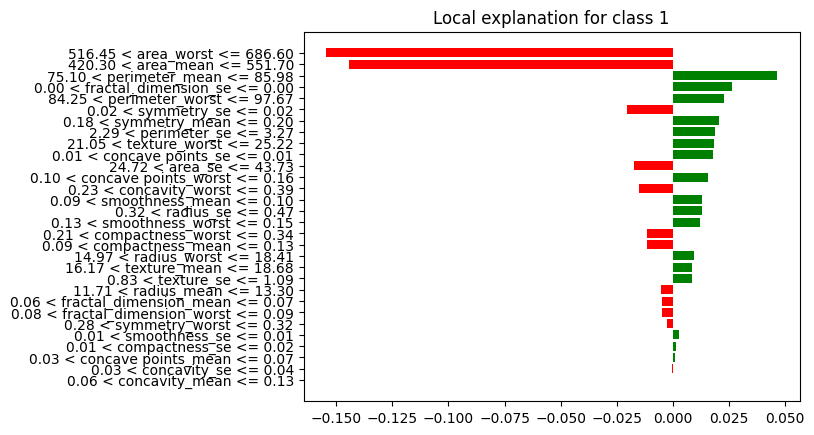

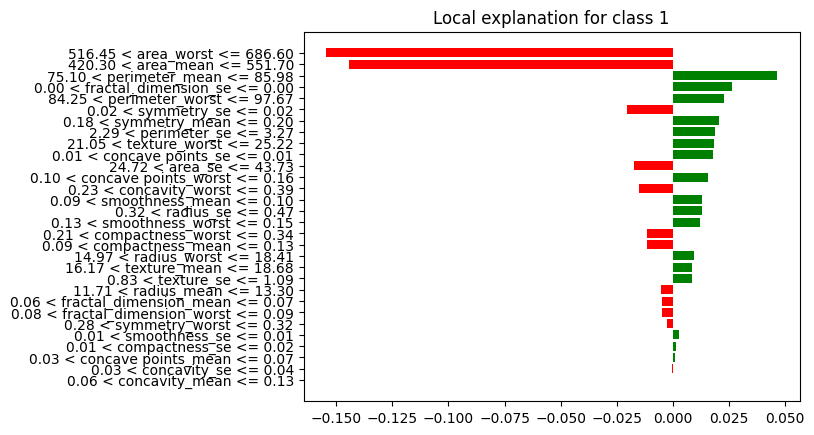

In [ ]:
exp.as_pyplot_figure()

In [ ]:
exp = explainer.explain_instance(mis.iloc[1], predict_fn, num_features=30)
exp.show_in_notebook(show_table=True, show_all=False)

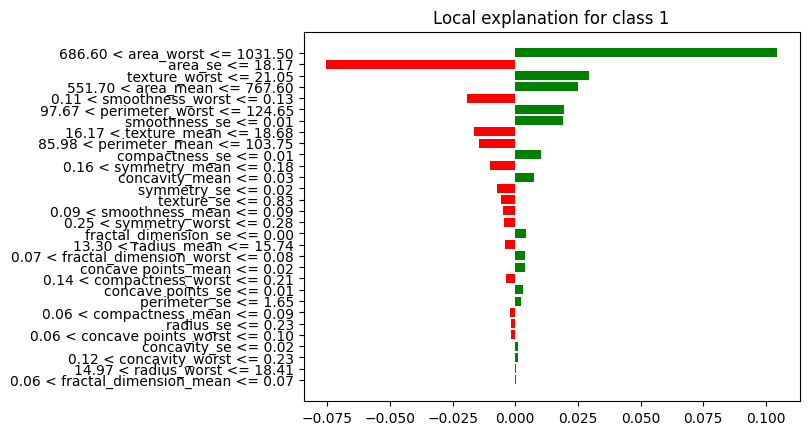

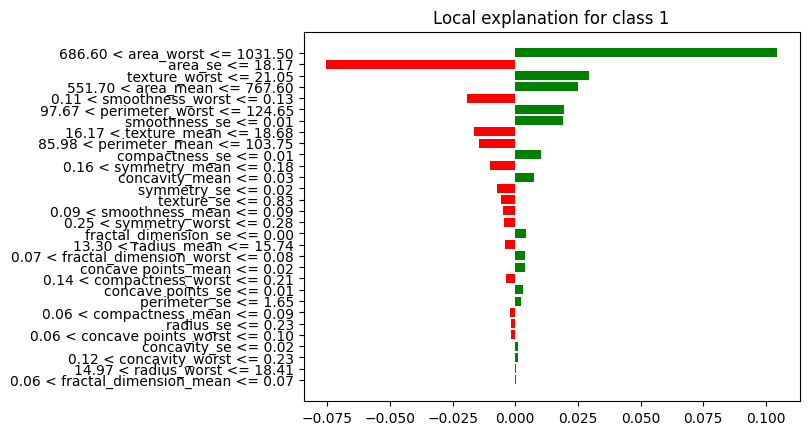

In [ ]:
exp.as_pyplot_figure()

In [ ]:
exp = explainer.explain_instance(mis.iloc[2], predict_fn, num_features=30)
exp.show_in_notebook(show_table=True, show_all=False)

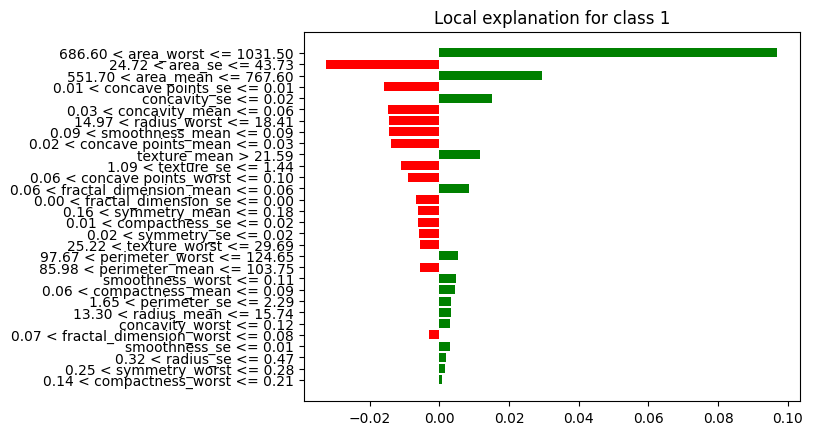

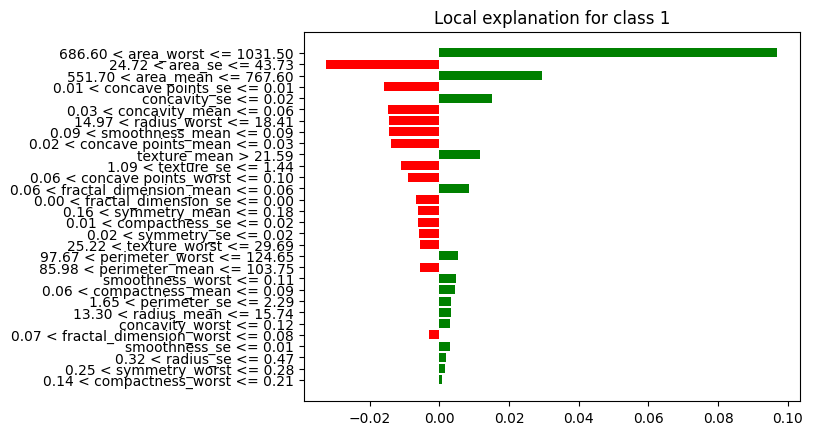

In [ ]:
exp.as_pyplot_figure()

## Instances with Low Confidence

In [ ]:
exp = explainer.explain_instance(low.iloc[0], predict_fn, num_features=30)
exp.show_in_notebook(show_table=True, show_all=False)

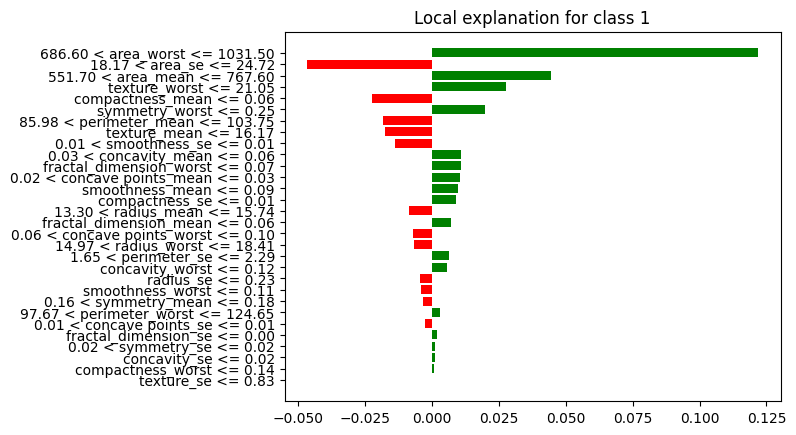

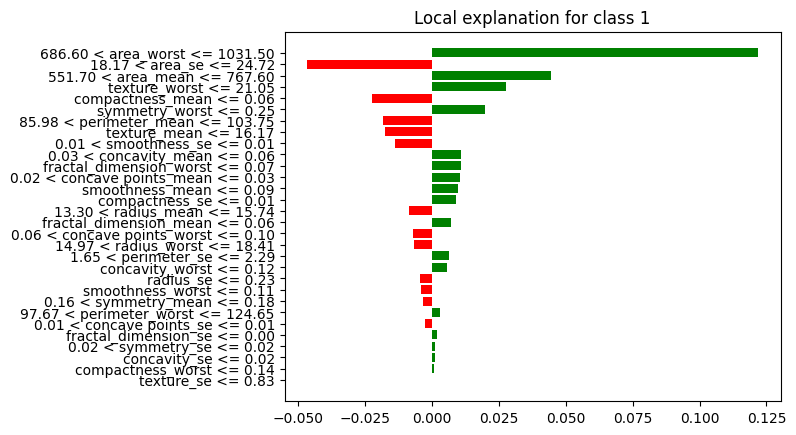

In [ ]:
exp.as_pyplot_figure()

In [ ]:
exp = explainer.explain_instance(low.iloc[1], predict_fn, num_features=30)
exp.show_in_notebook(show_table=True, show_all=False)

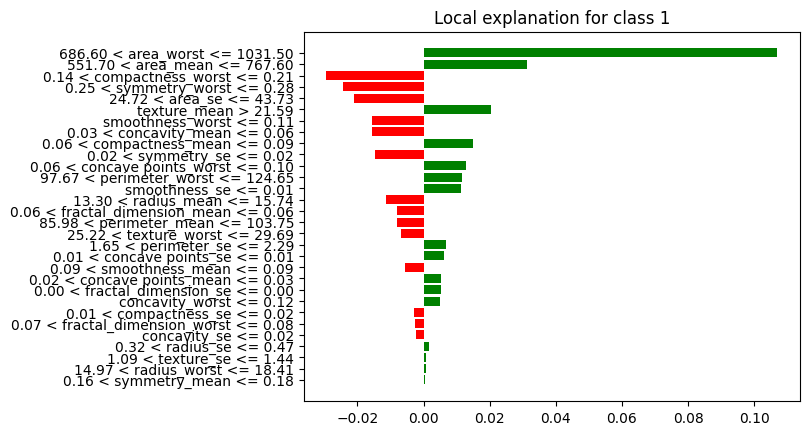

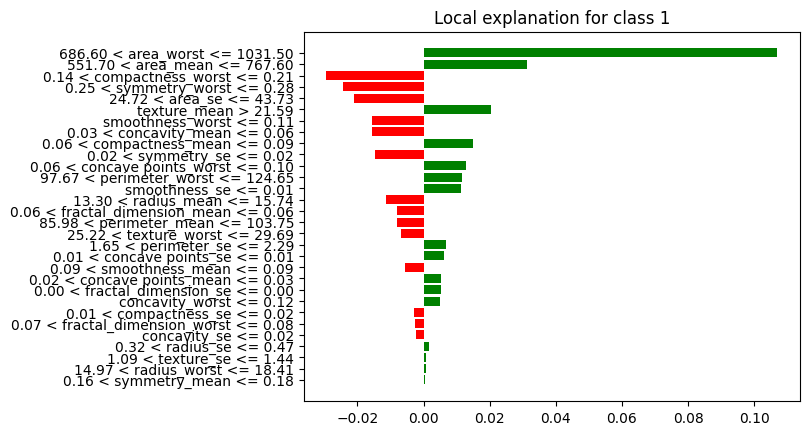

In [ ]:
exp.as_pyplot_figure()

In [ ]:
exp = explainer.explain_instance(low.iloc[2], predict_fn, num_features=30)
exp.show_in_notebook(show_table=True, show_all=False)

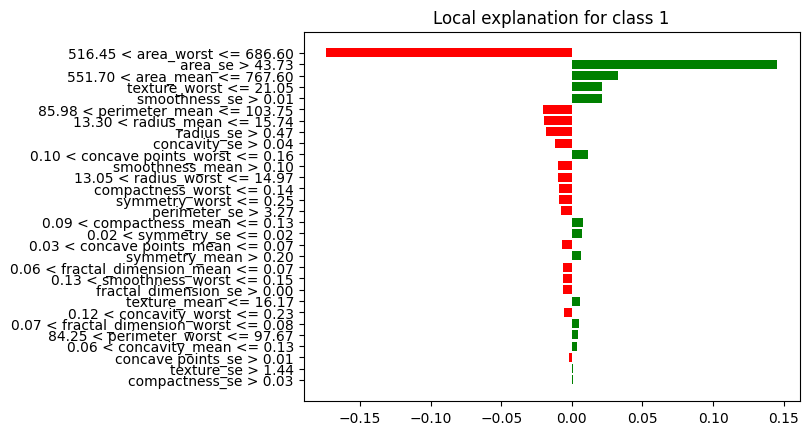

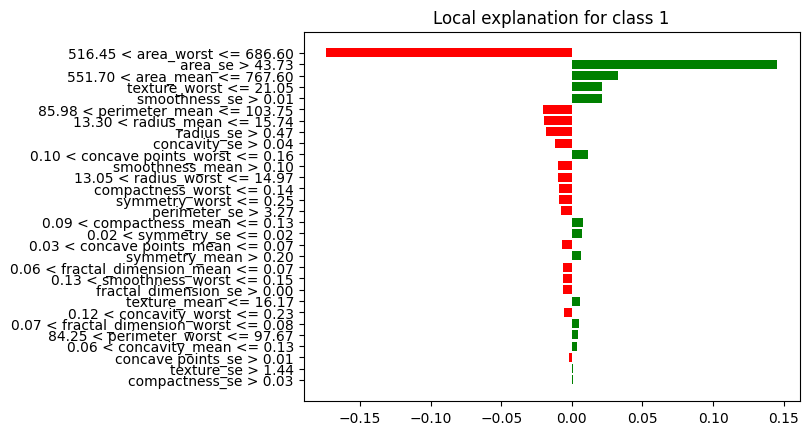

In [ ]:
exp.as_pyplot_figure()

## Instances with High Confidence

In [ ]:
exp = explainer.explain_instance(high.iloc[0], predict_fn, num_features=30)
exp.show_in_notebook(show_table=True, show_all=False)

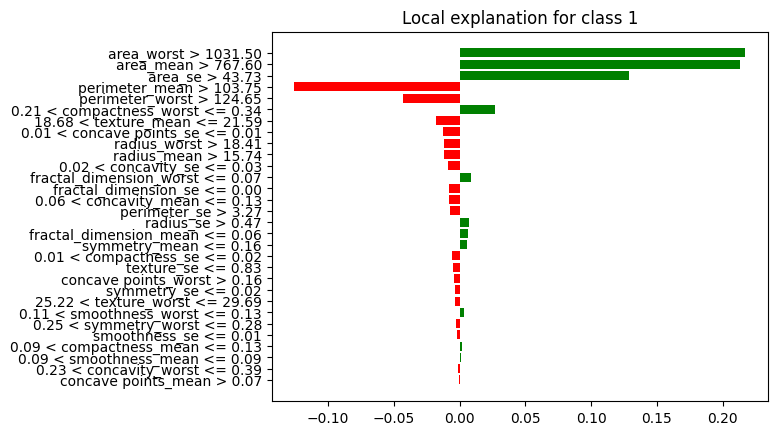

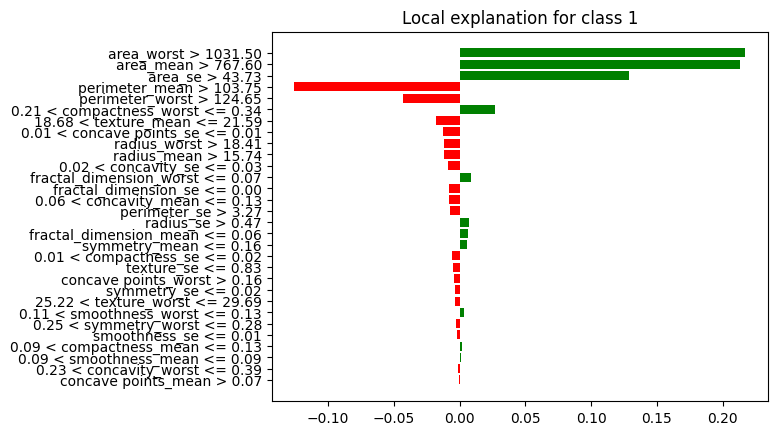

In [ ]:
exp.as_pyplot_figure()

In [ ]:
exp = explainer.explain_instance(high.iloc[1], predict_fn, num_features=30)
exp.show_in_notebook(show_table=True, show_all=False)

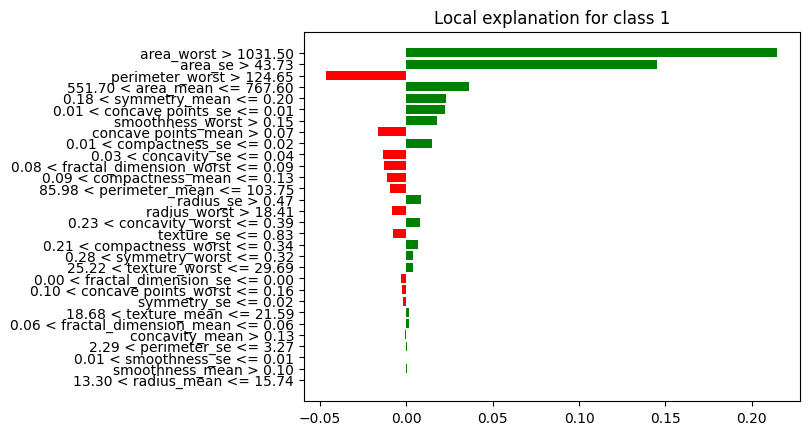

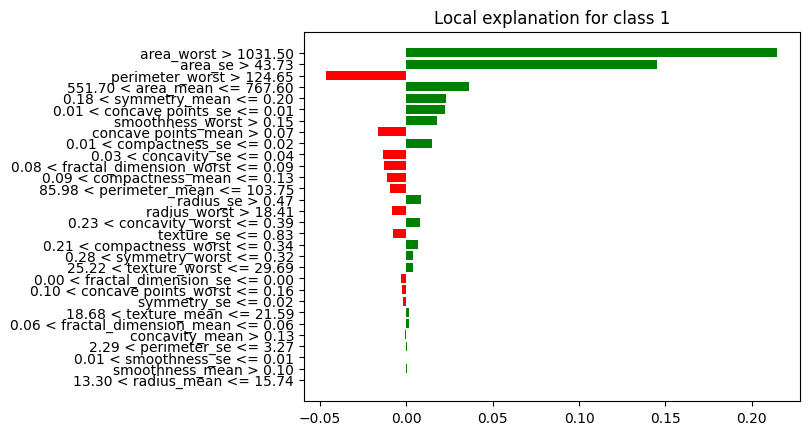

In [ ]:
exp.as_pyplot_figure()

In [ ]:
exp = explainer.explain_instance(high.iloc[2], predict_fn, num_features=30)
exp.show_in_notebook(show_table=True, show_all=False)

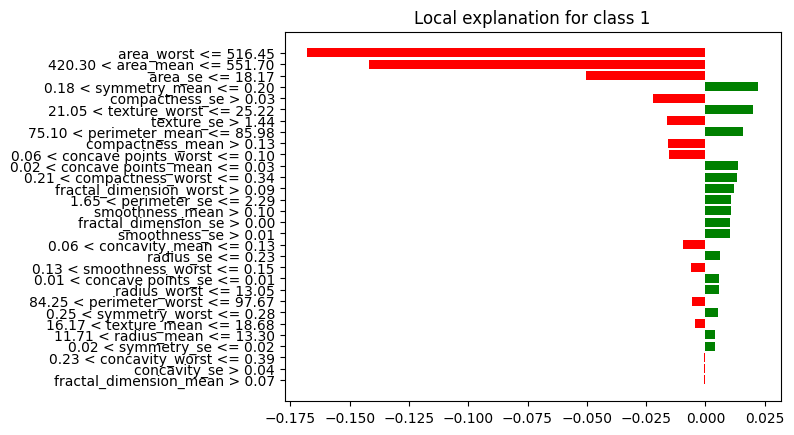

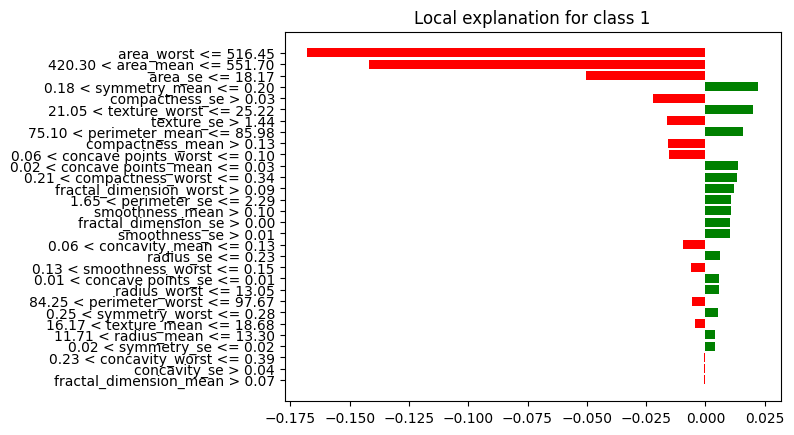

In [ ]:
exp.as_pyplot_figure()

In [ ]:
# # Wrapper function to make predictions with the PyTorch model
# def predict_fn(data):
#     model.eval()
#     with torch.no_grad():
#         data_tensor = torch.tensor(data, dtype=torch.float32)
#         predictions = model(data_tensor).numpy()
#     return predictions

# # Choose an instance to explain
# instance_index = 1
# exp = explainer.explain_instance(X_test[instance_index], predict_fn, num_features=4, top_labels=1)

# # Display the explanation
# exp.show_in_notebook(show_table=True)

In [ ]:
# inst = X_test.values[0]

In [ ]:
# exp = explainer.explain_instance(inst, bb.predict_proba)
# exp.show_in_notebook(show_table=True, show_all=False)

In [ ]:
# exp = explainer.explain_instance(inst, bb.predict_proba)
# exp.show_in_notebook(show_table=True, show_all=False)

In [ ]:
# exp = explainer.explain_instance(inst, bb.predict_proba, labels=[0])
# exp.show_in_notebook(show_table=True, show_all=False)

In [ ]:
# exp = explainer.explain_instance(inst, bb.predict_proba, num_features=5)
# exp.show_in_notebook(show_table=True, show_all=False)

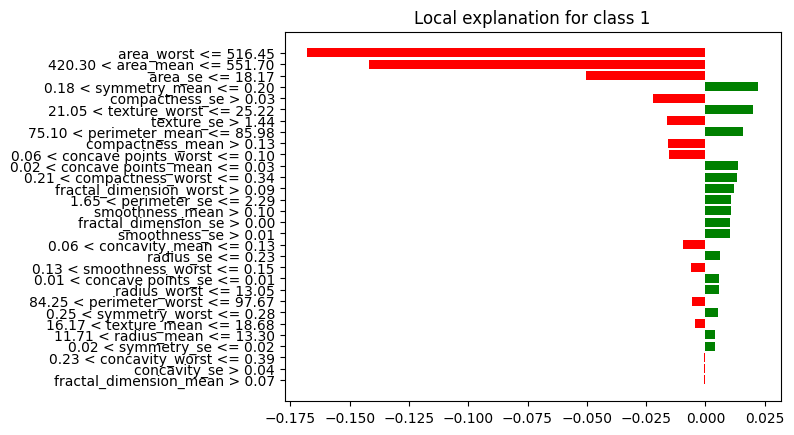

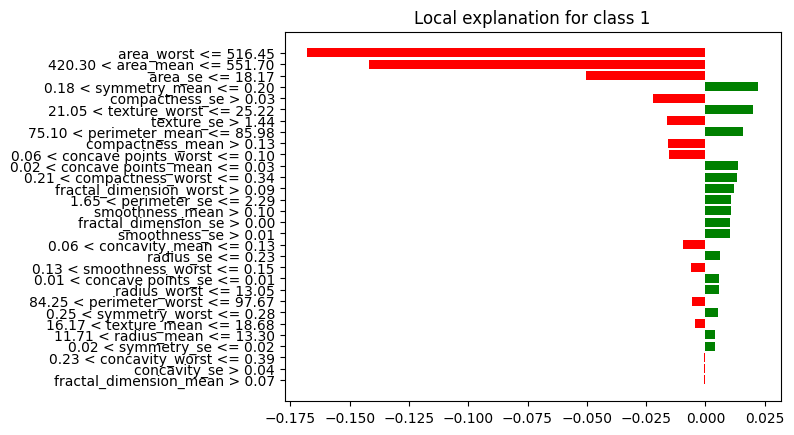

In [ ]:
exp.as_pyplot_figure()

# LORE

In [ ]:
# def predict_proba(self, x):
#     with torch.no_grad():
#         x = torch.tensor(x, dtype=torch.float32)
#         pred = torch.nn.functional.softmax(self.forward(x).cpu().detach())

#         return np.array(pred)

In [ ]:
# #LORE
# bbox = sklearn_classifier_wrapper(model)
# explainer = LoreTabularExplainer(bbox)

# inst_list = X_train[100:101] #list of lists
# inst_list[0] #list -- to give it to the explainer

# target = "diagnosis"

# explainer = LoreTabularExplainer(bbox)
# config = {'neigh_type':'rndgen', 'size':1000, 'ocr':0.1, 'ngen':10}
# explainer.fit(data, target, config)
# exp = explainer.explain(inst_list[0])
# print(exp)


# exp.plotRules()
# exp.plotCounterfactualRules()

In [ ]:
bbox = sklearn_classifier_wrapper(model)
explainer = LoreTabularExplainer(bbox)

In [ ]:
target = 'diagnosis'

In [ ]:
# compas_lore = X_train_.merge(y_train_,right_index=True, left_index=True)

In [ ]:
config = {'neigh_type':'rndgen', 'size':1000, 'ocr':0.1, 'ngen':10}
explainer.fit(data, target, config)

In [ ]:
# print('Instance ',X_test_[1])
# print('True class ',Y_test_[1])
# print('Predicted class ',bb.predict(inst.reshape(1, -1)))

**Get explanations and Counterfactuals examples for the 10 instances**

## Misclassified

In [ ]:
exp = explainer.explain(mis.iloc[0].values)
print(exp)

In [ ]:
exp.plotRules()

In [ ]:
exp.plotCounterfactualRules()

In [ ]:
# exp.getCounterExemplars()

In [ ]:
exp = explainer.explain(mis.iloc[1].values)
exp.plotRules()

In [ ]:
exp.plotCounterfactualRules()

In [ ]:
exp = explainer.explain(mis.iloc[2].values)
exp.plotRules()

In [ ]:
exp.plotCounterfactualRules()

## Instances with Low Confidence

In [ ]:
exp = explainer.explain(low.iloc[0].values)
exp.plotRules()

In [ ]:
exp.plotCounterfactualRules()

In [ ]:
exp = explainer.explain(low.iloc[1].values)
exp.plotRules()

In [ ]:
exp.plotCounterfactualRules()

In [ ]:
exp = explainer.explain(low.iloc[2].values)
exp.plotRules()

In [ ]:
exp.plotCounterfactualRules()

## Instances with High Confidence

In [ ]:
exp = explainer.explain(high.iloc[0].values)
exp.plotRules()

In [ ]:
exp.plotCounterfactualRules()

In [ ]:
exp = explainer.explain(high.iloc[1].values)
exp.plotRules()

In [ ]:
exp.plotCounterfactualRules()

In [ ]:
exp = explainer.explain(high.iloc[2].values)
exp.plotRules()

In [ ]:
exp.plotCounterfactualRules()

In [ ]:
exp = explainer.explain(high.iloc[3].values)
exp.plotRules()

In [ ]:
exp.plotCounterfactualRules()

# SHAP

In [ ]:
def f(x):
    model.eval()
    with torch.no_grad():
        x_tensor = torch.tensor(x, dtype=torch.float32)
        output = model(x_tensor)
        return F.softmax(output, dim=1).numpy()

In [ ]:
explainer = shap.KernelExplainer(model=f, data=X_train_[:50])

In [ ]:
shap_values = explainer.shap_values(X=X_test_[:10])

  0%|          | 0/10 [00:00<?, ?it/s]

In [ ]:
# Visualize the explanation for the first test example
shap.initjs()  # Initialize JavaScript visualization in Jupyter notebooks
shap.force_plot(base_value=explainer.expected_value[0], shap_values=shap_values[0][0], features=X_test_[0], feature_names=features_columns)


In [ ]:
# Visualize the explanation for the first test example
shap.initjs()  # Initialize JavaScript visualization in Jupyter notebooks
shap.force_plot(base_value=explainer.expected_value[0], shap_values=shap_values[0], features=X_test_[:10], feature_names=features_columns)

# Interpretable Model: Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
import numpy as np
import matplotlib.pyplot as plt


# Initialize and train logistic regression model
model = LogisticRegression()
model.fit(X_train_, y_train_)

LogisticRegression()

In [ ]:
# Print the coefficients
print("Coefficients (log odds):", model.coef_)

Coefficients (log odds): [[-1.18729907 -0.51567116 -0.13739033  0.01339158  0.04505652  0.21584064
   0.29831245  0.12752774  0.06724706  0.01360227 -0.04083591 -0.51104543
  -0.04311381  0.09366359  0.00420175  0.04434217  0.06114392  0.01641796
   0.01584365  0.00388621 -1.24856219  0.54821564  0.20627851  0.01460484
   0.08028862  0.65250215  0.8065715   0.23606627  0.21690699  0.06055259]]


In [ ]:
# Convert coefficients to odds ratios
odds_ratios = np.exp(model.coef_)
print("Odds Ratios:", odds_ratios)

Odds Ratios: [[0.30504406 0.59709971 0.87162994 1.01348165 1.04608699 1.24090461
  1.34758278 1.13601638 1.06955969 1.0136952  0.95998664 0.59986813
  0.95780238 1.09819024 1.00421059 1.04533998 1.0630519  1.01655347
  1.01596982 1.00389377 0.28691703 1.73016303 1.22909547 1.01471202
  1.08359977 1.92033981 2.24021424 1.26625823 1.24222855 1.06242347]]


In [ ]:
# # Plotting the odds ratios
# plt.figure(figsize=(10, 6))

# plt.bar(range(X_train_.shape[1]), odds_ratios[0])

# plt.xlabel('Feature')
# plt.ylabel('Odds Ratio')
# plt.title('Feature Importance (Odds Ratios)')
# plt.xticks(range(X_train_.shape[1]))
# plt.show()

In [ ]:
instances_to_explain = result.values
instances_to_explain.shape

(10, 30)

In [ ]:
pred = model.predict(instances_to_explain)
pred

array([0, 0, 0, 0, 0, 0, 1, 1, 0, 0])

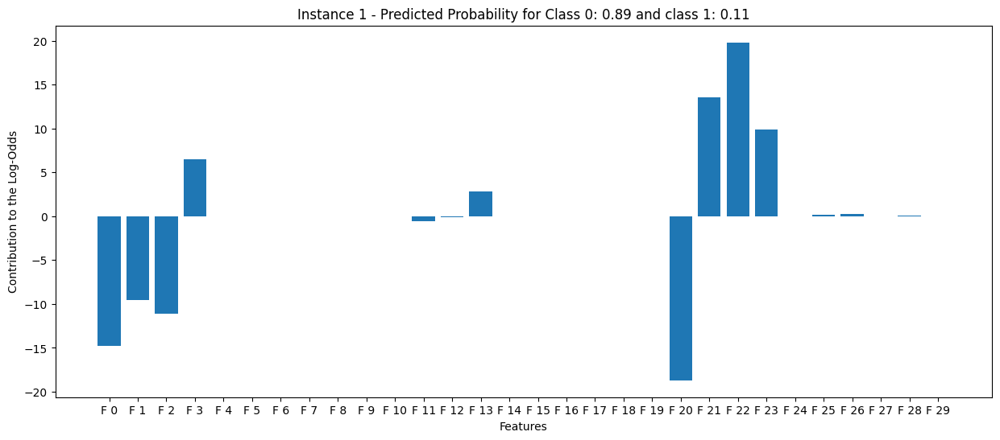

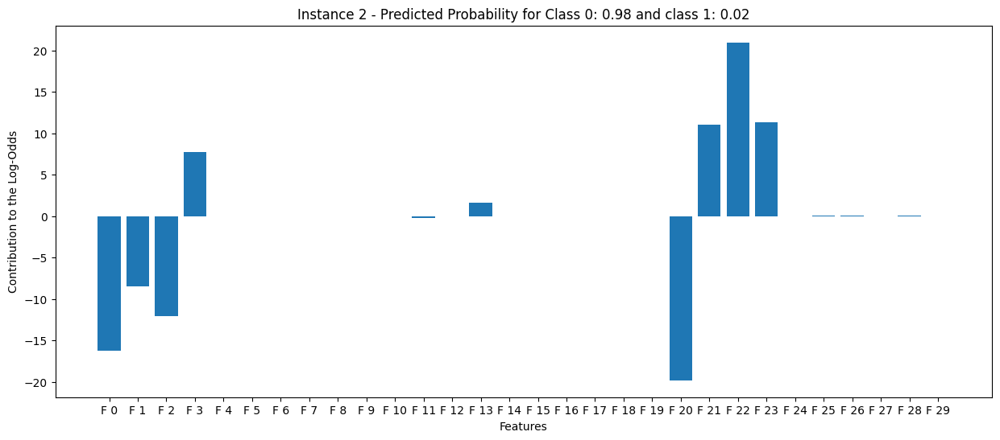

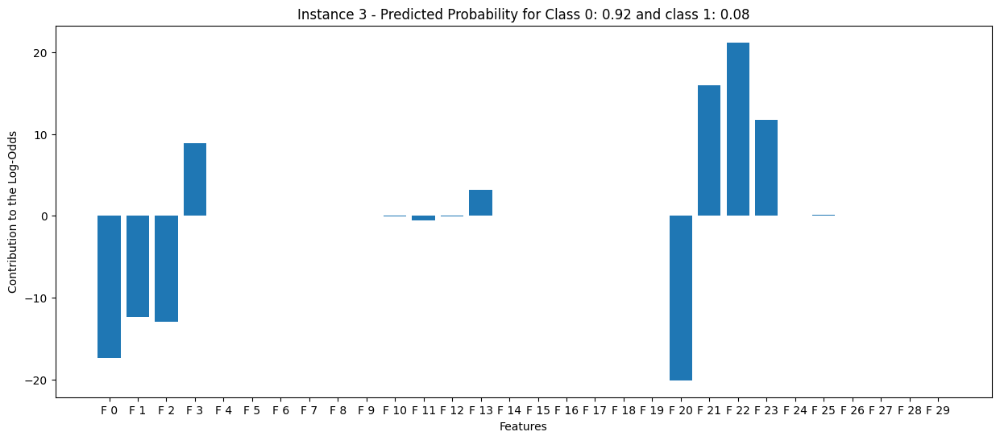

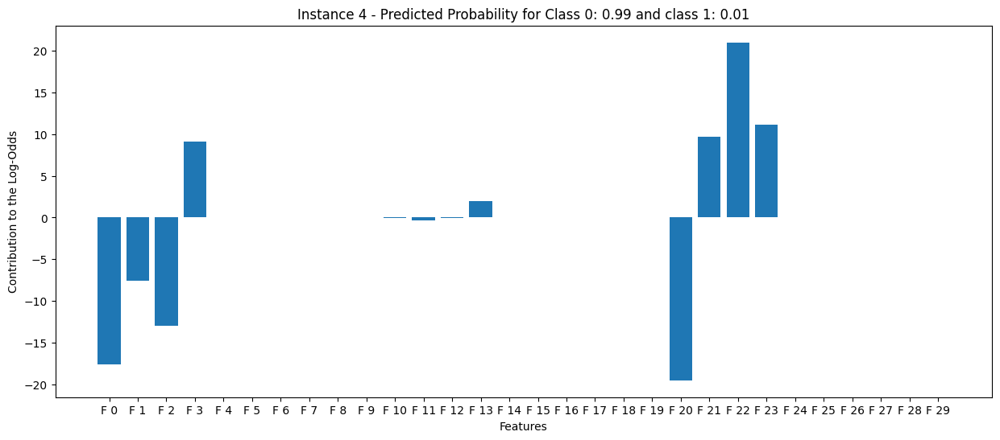

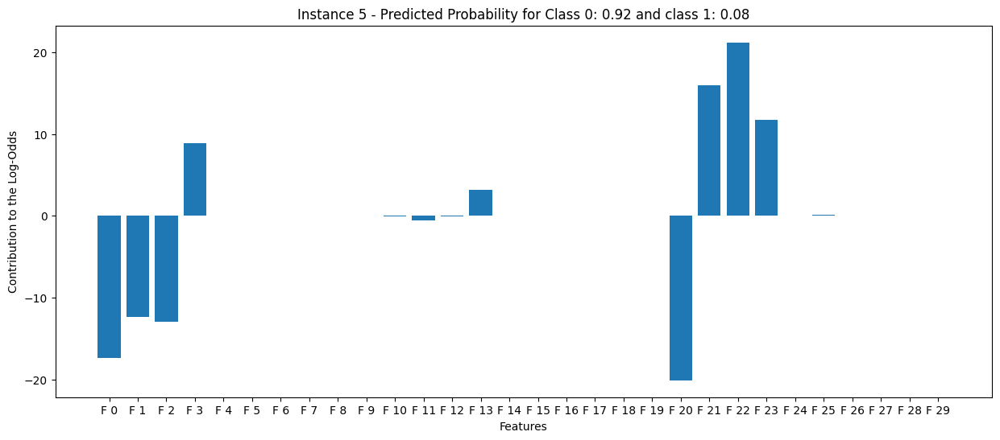

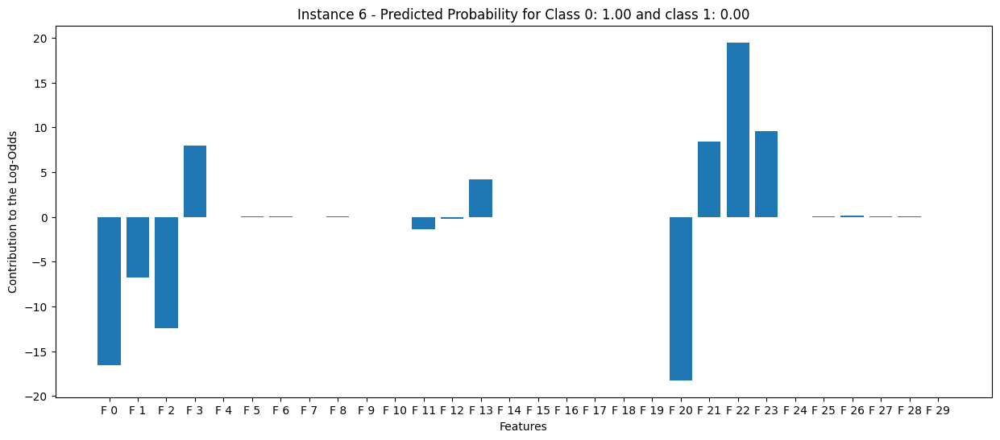

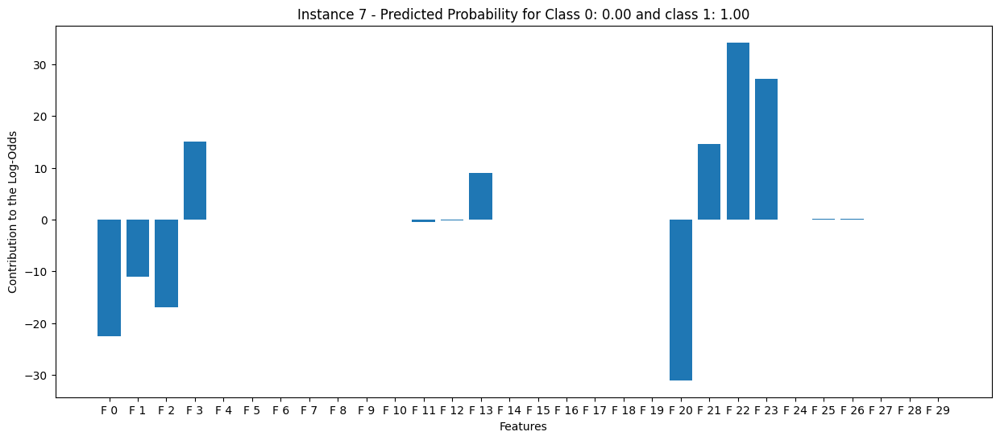

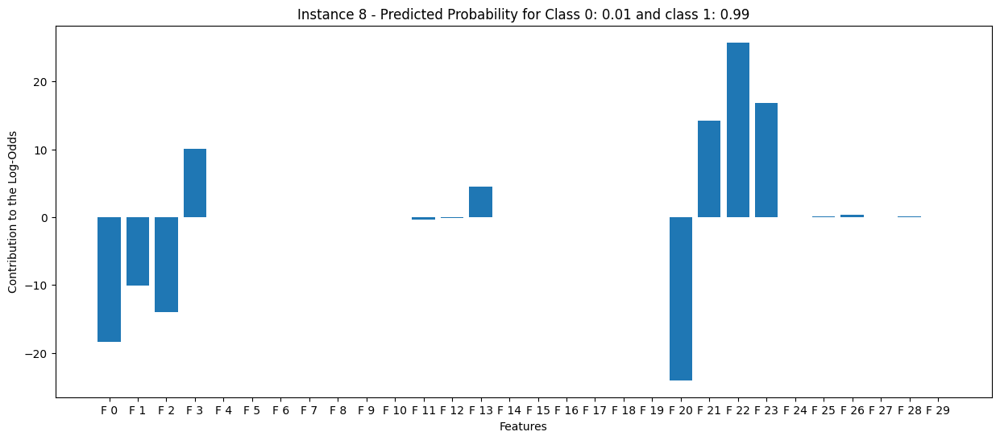

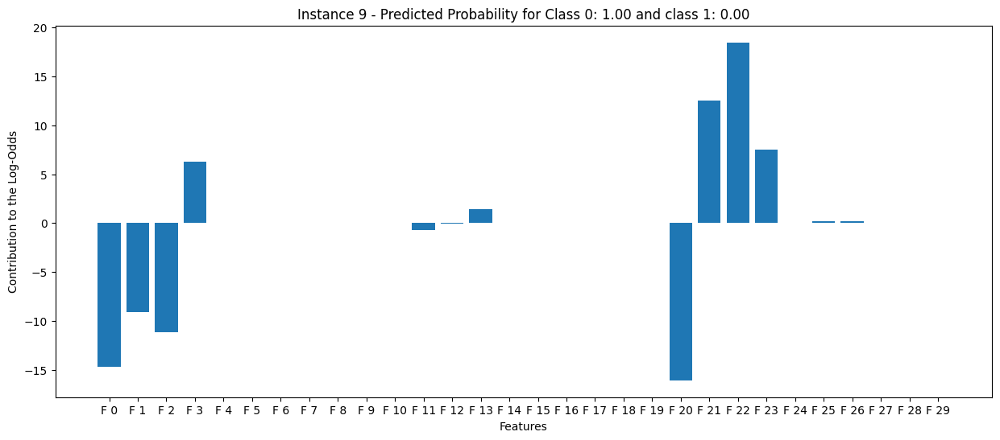

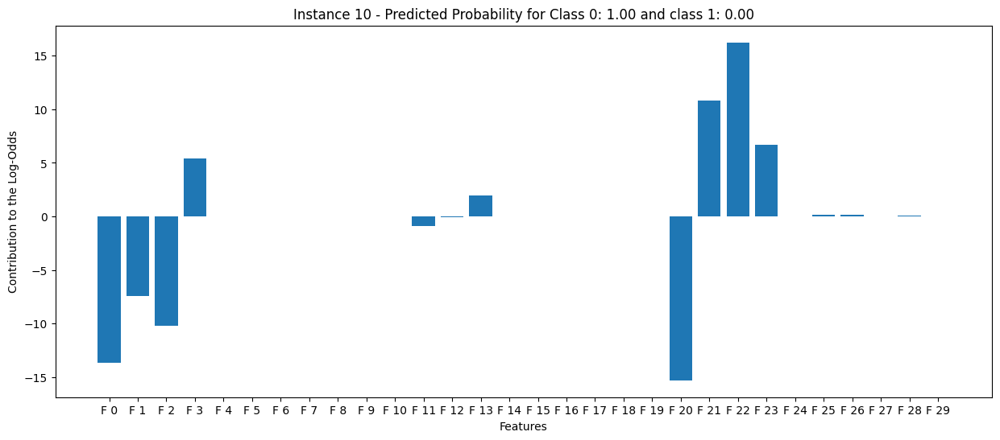

In [ ]:
# Predict probabilities
probs = model.predict_proba(instances_to_explain)

# Visualize explanations for each instance
for i, instance in enumerate(instances_to_explain):
    plt.figure(figsize=(15, 6))

    feature_contributions = instance * model.coef_[0]

    plt.bar(range(len(feature_contributions)), feature_contributions, tick_label=[f'F {j}' for j in range(len(feature_contributions))])

    plt.title(f'Instance {i+1} - Predicted Probability for Class 0: {probs[:,0][i]:.2f} and class 1: {probs[:,1][i]:.2f}')
    plt.xlabel('Features')
    plt.ylabel('Contribution to the Log-Odds')
    plt.show()

**Evaluate the fidelity of this Interpretable model**

**We are just comparing the prediction of the black box with the explainer on the 10 instances**

In [ ]:
#Pred are the predictions of the LogReg
#Predic are the prediction of the black box which is an NN: DiseaseClassifier
acc = accuracy_score(pred, predic)
acc

0.5

## Decision Tree

In [21]:
from interpret.glassbox import ClassificationTree
from interpret.glassbox import DecisionListClassifier
from interpret import show
from sklearn.metrics import roc_auc_score

In [30]:
dt = ClassificationTree(random_state=42)
dt.fit(X_train_, y_train_)

In [31]:
auc = roc_auc_score(y_test_, dt.predict_proba(X_test_)[:, 1])
print("AUC: {:.3f}".format(auc))

AUC: 0.957


In [32]:
show(dt.explain_global())

In [81]:
show(dt.explain_local(result.iloc[5:6], 1), 0)

In [51]:
result.columns

Index(['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
       'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')